#### Série: DuckDB Masterclass
**Ordem sugerida de leitura:** 1 de 14


📚 **Material de apoio — Laboratórios práticos no Jupyter Notebook**

Acompanhe os conceitos deste artigo com exemplos SQL, exercícios e laboratórios da DuckDB Masterclass.

🔗 [Acessar os laboratórios no GitHub](https://github.com/aestevaomoraes/duckdb-masterclass)


# DuckDB Masterclass — Capítulo 01

## Arquitetura OLAP in-process e decisões de desempenho

**Trilha:** conceito → teoria → laboratório → experimento → desafio → validação.

**Contexto:** Analytics e Engenharia de Dados, com exemplos de operações.

> Esta edição substitui os experimentos centrais por versões autocontidas. O material original está preservado integralmente na pasta `Originais/`. Quaisquer atividades dependentes de cloud/serviços externos são opcionais.

## 01.1 — Objetivos e diagnóstico inicial

**Ao final você deverá:** Diferencie OLAP de OLTP e interprete o plano de uma agregação.

**Pergunta de partida:** qual decisão analítica ou de engenharia está sendo tomada neste capítulo? Registre sua hipótese antes de executar o código.

## 01.2 — Conceito e teoria

O DuckDB executa consultas analíticas dentro do processo cliente. A execução vetorizada processa lotes de dados; não confunda um banco *in-process* com armazenamento exclusivamente em RAM. Benchmarks precisam controlar aquecimento, escala e ambiente.

**O que são OLTP e OLAP?**    
Imagine uma operadora de telecomunicações.

Ela possui sistemas que registram chamados, atualizam ordens de serviço e acompanham reparos. Ao mesmo tempo, seus gestores precisam analisar milhares ou milhões de registros para descobrir tendências operacionais.

Essas necessidades representam dois tipos diferentes de processamento.

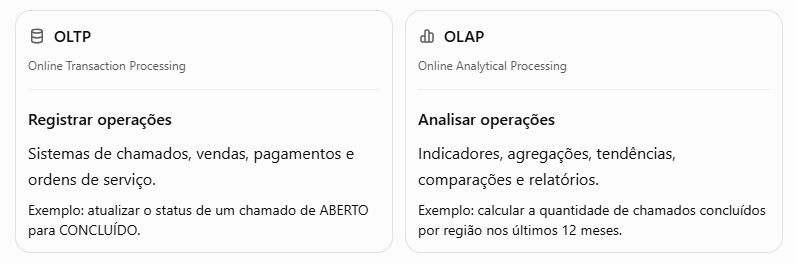    
O DuckDB foi desenvolvido principalmente para workloads analíticos, ou seja, OLAP.

**O que significa In-Process?**    
Significa que o mecanismo DuckDB pode ser executado dentro do processo da aplicação que o utiliza, por exemplo, um programa Python.

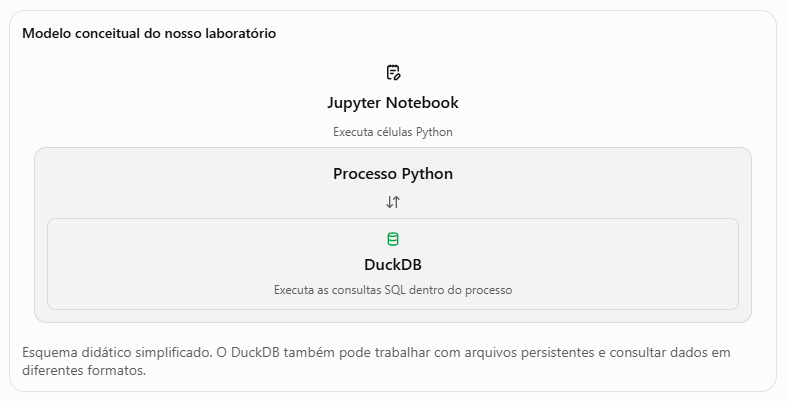

Em nosso notebook, isso aparece neste comando:

````python
con = duckdb.connect(':memory:')
````


`duckdb.connect()` estabelece uma conexão. O argumento ':memory:' cria um banco de dados em memória.

***Atenção a uma distinção:*** In-Process não significa que todos os dados precisam ficar exclusivamente na RAM. São características diferentes.

***Por que o DuckDB utiliza execução vetorizada?***   
Esse é um conceito central do Capítulo 01.


Imagine que precisamos somar os valores de 10.000 pedidos. Em vez de processar cada valor com toda a sobrecarga de uma operação individual, o DuckDB utiliza um mecanismo que processa conjuntos de valores em lotes, chamados vetores.

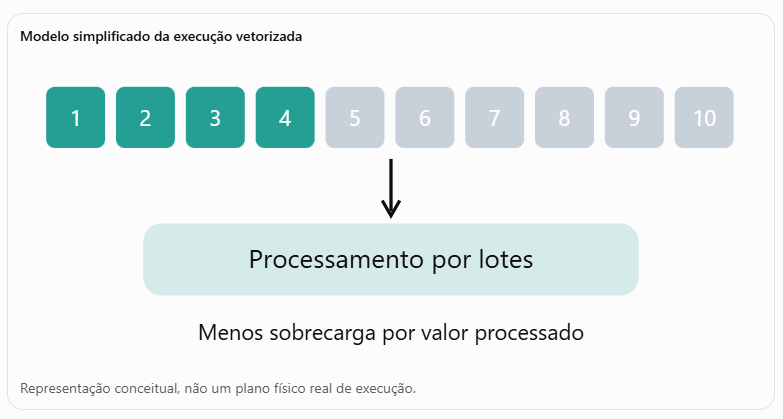

*o duckdb combina uma arquitetura analítica com execução vetorizada. isso favorece consultas com grandes volumes, agregações e transformações, embora o desempenho dependa também dos dados, da consulta e dos recursos disponíveis.*

### Modelo mental

- **Entrada:** que dados ou recursos estão disponíveis?
- **Operação:** o que o DuckDB transforma, consulta ou controla?
- **Saída:** que informação ou garantia pode ser verificada?
- **Limite:** o que o laboratório **não** permite concluir?

## 01.3 — Preparação reproduzível

Execute a célula a seguir. Caso falte DuckDB, instale com `pip install duckdb pandas` no ambiente virtual utilizado pelo Jupyter e reinicie o kernel. Reiniciar o kernel apaga conexões em memória.

In [1]:
import duckdb
from IPython.display import display
print('DuckDB:', duckdb.__version__)
con = duckdb.connect(':memory:')

DuckDB: 2.0.0


## 01.4 — Laboratório guiado

**Previsão:** antes de executar, descreva em uma frase o resultado esperado.

**Interpretação:** depois de executar, explique o que cada coluna ou efeito representa.

In [3]:
# 1. Definição das consultas SQL em blocos multilinhas limpos
QUERY_CRIAR_PEDIDOS = """
    CREATE OR REPLACE TABLE pedidos AS
    SELECT 
        i AS pedido_id,
        'R' || CAST(i % 5 AS VARCHAR) AS regiao,
        (i % 100 + 1)::INTEGER AS receita
    FROM range(10000) AS t(i);
"""

QUERY_AGRUPAMENTO_REGIAO = """
    SELECT 
        regiao,
        COUNT(*) AS n,
        SUM(receita) AS total
    FROM pedidos
    GROUP BY ALL
    ORDER BY regiao;
"""

# 2. Execução da criação dos dados sintéticos
con.execute(QUERY_CRIAR_PEDIDOS)

# 3. Consulta analítica e conversão para DataFrame
df_resumo_regiao = con.execute(QUERY_AGRUPAMENTO_REGIAO).df()
display(df_resumo_regiao)

# 4. Teste de integridade/qualidade de dados (Data Quality)
total_registros = df_resumo_regiao["n"].sum()
assert total_registros == 10000, f"Falha na validação: esperado 10000 registros, encontrado {total_registros}"

,regiao,n,total
0,R0,2000,97000.0
1,R1,2000,99000.0
2,R2,2000,101000.0
3,R3,2000,103000.0
4,R4,2000,105000.0


### 🧠 Nota técnica — Distribuição determinística dos dados

O laboratório utiliza `range(10000)` para gerar 10.000 registros.

A expressão `i % 5` calcula o resto da divisão de cada identificador por 5, produzindo cinco categorias: R0, R1, R2, R3 e R4.

Como 10.000 é divisível por 5, cada região recebe exatamente 2.000 pedidos.

A expressão `i % 100 + 1` determina os valores de receita, que variam de 1 a 100.

**Observação:** embora as regiões tenham a mesma quantidade de pedidos, suas receitas totais são diferentes porque os valores gerados estão associados ao identificador de cada registro.

**Aprendizado:** dados sintéticos determinísticos permitem reproduzir resultados e validar consultas SQL sem depender de aleatoriedade.

O laboratório ensina três operações importantes:
- `COUNT(*):` quantidade de pedidos por região.
- `SUM(receita):` receita total por região.
- `GROUP BY ALL:` agrupa pelas expressões selecionadas que não são agregações.




## 01.5 — Experimentação controlada: entendendo o EXPLAIN

### 🎯 Objetivo

Investigar como o DuckDB planeja uma consulta SQL que agrupa 10.000 pedidos em cinco regiões.

O comando `EXPLAIN` apresenta o plano físico escolhido pelo otimizador, sem executar a consulta para produzir os resultados analíticos.

**Pergunta de investigação:** quais operações o DuckDB utiliza para ler os pedidos e calcular a receita total por região?

Antes de executar, formule uma hipótese.


In [4]:
display(con.execute("EXPLAIN SELECT regiao, SUM(receita) FROM pedidos GROUP BY ALL").df())

,explain_key,explain_value
0,physical_plan,╭─ Projection ─────────────────────────────╮\n...


#### 🔬 Laboratório 01.5.1 - Consulta A — Sem filtro

Analisa todas as regiões

In [5]:
plano = con.execute("""
    EXPLAIN
    SELECT
        regiao,
        SUM(receita) AS receita_total
    FROM pedidos
    GROUP BY ALL
""").fetchone()[1]

print(plano)

╭─ Projection ─────────────────────────────╮
│ Projections:                             │
│ __internal_decompress_string(#0), #1     │
│ ~5 rows                                  │
╰─────────────────────┬────────────────────╯
╭─ Hash Group By ─────┴────────────────────╮
│ Groups: #0                               │
│ Aggregates: sum_no_overflow(#1)          │
│ ~5 rows                                  │
╰─────────────────────┬────────────────────╯
╭─ Projection ────────┴────────────────────╮
│ Projections: regiao, receita             │
│ ~10,000 rows                             │
╰─────────────────────┬────────────────────╯
╭─ Projection ────────┴────────────────────╮
│ Projections:                             │
│ __internal_compress_string_uinteger(#0), │
│ #1                                       │
│ ~10,000 rows                             │
╰─────────────────────┬────────────────────╯
╭─ Seq Scan ──────────┴────────────────────╮
│ Table: memory.main.pedidos               │
│ Type: Se


### 🧠 Nota técnica — Interpretando o plano de execução

O `EXPLAIN` apresenta o plano físico escolhido pelo otimizador do DuckDB.

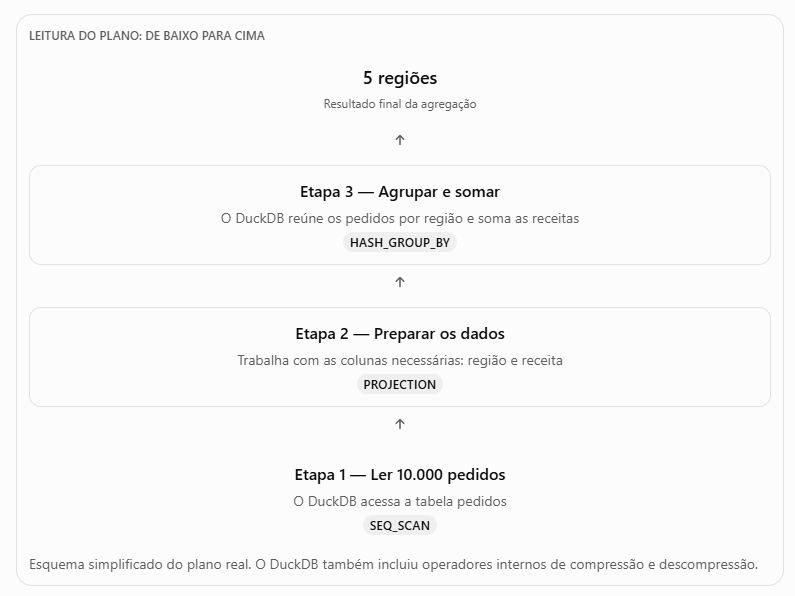

**Leitura do plano: de baixo para cima.**

1. `SEQ_SCAN`: leitura das colunas `regiao` e `receita`.
2. `PROJECTION`: preparação de colunas e representações internas.
3. `HASH_GROUP_BY`: agrupamento por região e soma das receitas.
4. `PROJECTION` final: preparação do resultado agregado.

**Estimativas observadas:**
- Entrada: aproximadamente 10.000 linhas.
- Saída: aproximadamente 5 grupos.

O símbolo `~` identifica estimativas do otimizador, não medições reais.

**Aprendizado:** o `EXPLAIN` permite compreender como o DuckDB pretende executar uma consulta. Para investigar a execução efetiva e seus tempos, utilizamos `EXPLAIN ANALYZE`.


*O HASH_GROUP_BY reúne os pedidos por região e calcula SUM(receita), produzindo cinco totais no nosso laboratório.*


#### 🔬 Laboratório 01.5.2 - Consulta B — Com filtro

Analisa somente R0

In [6]:
plano_filtrado = con.execute("""
    EXPLAIN
    SELECT
        regiao,
        SUM(receita) AS receita_total
    FROM pedidos
    WHERE regiao = 'R0'
    GROUP BY ALL
""").fetchone()[1]

print(plano_filtrado)

╭─ Projection ─────────────────────────────╮
│ Projections:                             │
│ __internal_decompress_string(#0), #1     │
│ ~5 rows                                  │
╰─────────────────────┬────────────────────╯
╭─ Hash Group By ─────┴────────────────────╮
│ Groups: #0                               │
│ Aggregates: sum_no_overflow(#1)          │
│ ~5 rows                                  │
╰─────────────────────┬────────────────────╯
╭─ Projection ────────┴────────────────────╮
│ Projections: regiao, receita             │
│ ~2,000 rows                              │
╰─────────────────────┬────────────────────╯
╭─ Projection ────────┴────────────────────╮
│ Projections:                             │
│ __internal_compress_string_uinteger(#0), │
│ #1                                       │
│ ~2,000 rows                              │
╰─────────────────────┬────────────────────╯
╭─ Seq Scan ──────────┴────────────────────╮
│ Table: memory.main.pedidos               │
│ Type: Se

#### Conceito novo: Filter Pushdown

O *Filter Pushdown* é uma otimização em que o filtro pode ser aplicado o mais cedo possível no processamento, reduzindo a quantidade de registros encaminhados aos operadores seguintes.

Não significa necessariamente que menos linhas serão lidas fisicamente. Isso depende do armazenamento e de outras otimizações.

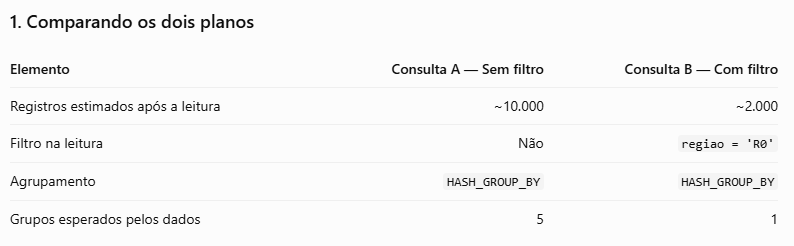



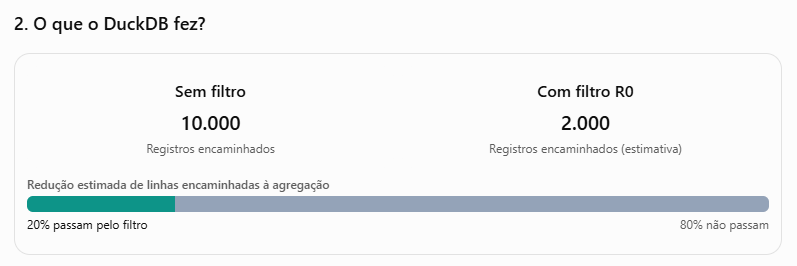



### 🧠 Conclusão — Consulta B

Ao adicionar `WHERE regiao = 'R0'`, o DuckDB incorporou o filtro ao operador `SEQ_SCAN`.

**Comparação com a Consulta A:**

- Sem filtro: aproximadamente 10.000 linhas.
- Com filtro: aproximadamente 2.000 linhas.
- O `HASH_GROUP_BY` permaneceu, pois a consulta ainda realiza uma agregação.

**Aprendizado:** o filtro reduziu a quantidade estimada de registros encaminhados às operações seguintes.

**Atenção:** o `EXPLAIN` apresenta estimativas, não contagens reais. Por isso, mesmo filtrando apenas R0, o plano ainda estimou aproximadamente cinco grupos.


#### 🎓 Para Guardar
- **EXPLAIN:** mostra o plano de execução escolhido pelo DuckDB. Não é uma otimização.
- **Filter Pushdown:** é a otimização que permite aplicar o filtro antecipadamente, reduzindo os registros encaminhados às próximas operações.

### 🔬 Laboratório 01.5.3 — Validando os resultados reais da consulta com filtro

**Objetivo:** executar a consulta SQL e verificar se a região R0 apresenta exatamente 2.000 pedidos e uma receita total de 97.000, comparando os resultados efetivos com as estimativas do `EXPLAIN`.

In [7]:
resultado_filtrado = con.execute("""
    SELECT
        regiao,
        COUNT(*) AS pedidos,
        SUM(receita) AS receita_total
    FROM pedidos
    WHERE regiao = 'R0'
    GROUP BY ALL
""").df()

display(resultado_filtrado)

,regiao,pedidos,receita_total
0,R0,2000,97000.0



**Conclusão:** a consulta retornou 2.000 pedidos e receita total de 97.000 para a região R0, confirmando os valores esperados.

A estimativa de aproximadamente 2.000 linhas no `SEQ_SCAN` coincidiu com a quantidade real de registros filtrados.

Essa coincidência não significa que o `EXPLAIN` realizou uma medição da execução.


### 🔬 Laboratório 01.5.4 — EXPLAIN ANALYZE: analisando a execução efetiva

In [8]:
plano_analisado = con.execute("""
    EXPLAIN ANALYZE
    SELECT
        regiao,
        COUNT(*) AS pedidos,
        SUM(receita) AS receita_total
    FROM pedidos
    WHERE regiao = 'R0'
    GROUP BY ALL
""").fetchone()[1]

print(plano_analisado)

╭─ Summary ───────────╮
│ Total Time: 0.0217s │
╰─────────────────────╯
╭─ Projection ─────────────────────────────╮
│ Projections:                             │
│ __internal_decompress_string(#0), #1, #2 │
│ 1 row                                0µs │
╰─────────────────────┬────────────────────╯
╭─ Hash Group By ─────┴────────────────────╮
│ Groups: #0                               │
│ Aggregates: count_star(),                │
│             sum_no_overflow(#1)          │
│ 1 row                                0µs │
╰─────────────────────┒┎───────────────────╯
╭─ Projection ────────┚┖───────────────────╮
│ Projections: regiao, receita             │
│ 2,000 rows                           0µs │
╰─────────────────────┒┎───────────────────╯
╭─ Projection ────────┚┖───────────────────╮
│ Projections:                             │
│ __internal_compress_string_uinteger(#0), │
│ #1                                       │
│ 2,000 rows                           0µs │
╰─────────────────────┒┎────


### 🧠 Conclusão — EXPLAIN vs. EXPLAIN ANALYZE

O `EXPLAIN` apresenta o plano físico e as estimativas do otimizador.

O `EXPLAIN ANALYZE` executa a consulta e apresenta métricas observadas.

**Resultados do laboratório:**
- Tempo total: 21,7 ms.
- Registros após o filtro: 2.000.
- Grupos produzidos: 1 (região R0).

A estimativa de 2.000 linhas coincidiu com a execução real, mas a estimativa de cinco grupos não.

**Aprendizado:** utilizar `EXPLAIN ANALYZE` para investigar o comportamento efetivo da consulta, sem tirar conclusões de desempenho com base em uma única execução.


## 01.6 — Desafio profissional

Por que o tempo de uma consulta isolada não é evidência de superioridade de desempenho? Compare duas execuções e explique a variabilidade.

**Critérios de aceite:** descreva a regra de negócio, escreva uma consulta/experimento, valide o resultado e explique pelo menos uma limitação.

**Solução:** registre sua resposta na célula abaixo antes de consultar o material original.

In [9]:
# Sua solução: escreva aqui seu experimento ou explicação.
import time
import statistics

tempos_ms = []

query = """
    SELECT
        regiao,
        SUM(receita) AS receita_total
    FROM pedidos
    GROUP BY ALL
"""

for i in range(10):
    inicio = time.perf_counter()

    con.execute(query).fetchall()

    duracao_ms = (time.perf_counter() - inicio) * 1000
    tempos_ms.append(duracao_ms)

    print(f"Execução {i+1:02d}: {duracao_ms:.3f} ms")

print(f"\nMediana: {statistics.median(tempos_ms):.3f} ms")
print(f"Mínimo:  {min(tempos_ms):.3f} ms")
print(f"Máximo:  {max(tempos_ms):.3f} ms")


Execução 01: 13.035 ms
Execução 02: 5.709 ms
Execução 03: 14.179 ms
Execução 04: 5.528 ms
Execução 05: 3.985 ms
Execução 06: 6.944 ms
Execução 07: 4.702 ms
Execução 08: 14.162 ms
Execução 09: 9.852 ms
Execução 10: 5.480 ms

Mediana: 6.326 ms
Mínimo:  3.985 ms
Máximo:  14.179 ms


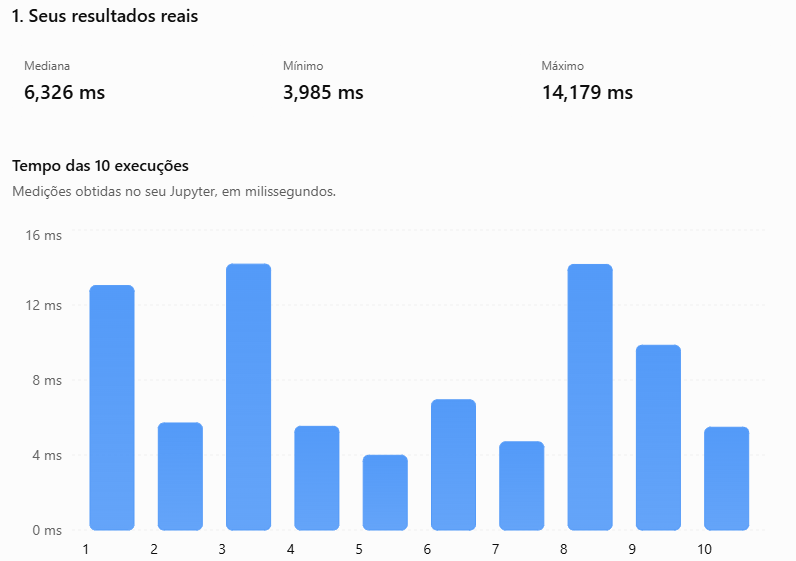


### 🧠 Conclusão — Variabilidade de desempenho

Foram realizadas 10 execuções da mesma consulta SQL.

**Resultados observados:**
- Mediana: 6,326 ms.
- Menor tempo: 3,985 ms.
- Maior tempo: 14,179 ms.

Apesar de utilizar a mesma consulta e os mesmos dados, os tempos variaram significativamente.

Essa diferença pode ocorrer devido à atividade da CPU, ao sistema operacional, ao cache e à sobrecarga da aplicação Python.

**Aprendizado:** uma única medição não é suficiente para avaliar o desempenho de uma consulta SQL.

Para comparações confiáveis, devemos realizar múltiplas execuções, controlar as condições do experimento e utilizar métricas estatísticas.


## 01.7 — Autoavaliação e visão de especialista

> O SEQ_SCAN representa a leitura dos dados, com uma estimativa de  linhas. O HASH_GROUP_BY representa o agrupamento desses registros, com uma estimativa de  grupos. Esses valores não são medições reais porque foram calculados pelo otimizador durante o planejamento da consulta.

> A padronização dos dados é essencial para garantir a confiabilidade dos indicadores. Como o filtro `WHERE status = 'CONCLUIDO'` realiza uma comparação exata, registros com valores diferentes, como `CONCLUÍDO`, não serão considerados. O **dbt** é uma excelente ferramenta para centralizar essas regras de transformação na camada **Staging**, padronizando os dados antes das análises e evitando inconsistências nos indicadores operacionais.

> **Diagnóstico de degradação de desempenho**    
> Primeiro, realizaria medições repetidas, utilizando a mediana para verificar se a lentidão é persistente e não resultado de fatores externos.    
> Em seguida, utilizaria o `EXPLAIN` para analisar o plano físico da consulta e identificar possíveis operações ineficientes.    
> Por fim, aplicaria o `EXPLAIN ANALYZE` para observar os tempos e as quantidades reais de linhas processadas, buscando identificar os gargalos.
>   
> **Conclusão:** a investigação de desempenho deve combinar medições reproduzíveis, análise do plano de execução e validação das métricas observadas.    


3. Cite um erro de dados ou de configuração que poderia invalidar o resultado.
4. Explique como você verificaria esse erro.
5. Relacione a técnica a um caso real de Operations Analytics.

**Próximo passo da mentoria:** revisar suas respostas e os resultados de execução antes de avançar.

## 01.8 — Leituras e materiais originais

- [Documentação oficial DuckDB](https://duckdb.org/docs/stable/) — consulte o tópico específico antes de usar recursos em produção.
- Consulte o notebook de mesmo nome em `Originais/` para exemplos históricos e contexto adicional.

**Estado de validação:** estrutura e sintaxe Python verificadas no empacotamento; consultas SQL requerem execução no ambiente com DuckDB.